In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import argos
from argos import ArgosDataset

## Importando

In [2]:
metadata = pd.read_csv("../data/processed/metadata_filtrada.csv")
ids_finais = metadata["sample"].tolist()
print(ids_finais)

['GCA_000216055.2', 'GCA_000316425.1', 'GCA_000223095.2', 'GCA_036761135.1', 'GCA_003670255.1', 'GCA_006334885.1', 'GCA_006334895.1', 'GCA_024700995.1', 'GCA_024701035.1', 'GCF_000363915.2', 'GCA_000348045.1', 'GCA_000348065.1', 'GCA_000327825.2', 'GCA_000328125.2', 'GCA_000327845.2', 'GCA_000327865.2', 'GCA_021538905.1', 'GCA_000355215.1', 'GCA_000355195.1', 'GCA_000355235.1', 'GCA_000355255.1', 'GCA_000512165.1', 'GCA_041901425.1', 'GCA_023093655.1', 'GCA_026223635.2', 'GCA_000386205.2', 'GCA_000386225.2', 'GCA_000386745.2', 'GCA_000386765.2', 'GCA_003859745.1', 'GCA_018224045.1', 'GCA_000306435.2', 'GCA_000346675.1', 'GCA_000306135.2', 'GCA_000350585.1', 'GCA_000369605.1', 'GCA_000346655.1', 'GCA_011463375.1', 'GCA_030668605.1', 'GCA_031192385.1', 'GCA_028067445.1', 'GCA_020622285.1', 'GCA_025823245.1', 'GCA_002102185.1', 'GCF_000647855.2', 'GCF_001921685.1', 'GCF_001921695.1', 'GCA_002260005.1', 'GCA_002260015.1', 'GCA_002260065.1', 'GCA_002260085.1', 'GCA_002267625.1', 'GCA_002267

In [3]:
pr_ids = metadata[metadata['Estado'] == 'PR']
pr_finais = pr_ids["sample"].tolist()
len(pr_finais)

297

In [4]:
dataset = ArgosDataset.from_parquet("../data/argos_project/parquet_data", samples=pr_finais)
dataset.resistome.head()

,ORF_ID,Cut_Off,Pass_Bitscore,Best_Hit_Bitscore,Best_Identities,drug_class,mechanism,amr_gene_family,Predicted_Protein,CARD_Protein_Sequence,...,gene,aro_accession,model_type,gene_clean,seq_name,start,end,strand,length_nt,contig_type
0,JTUI01000001.1_17 # 22866 # 24161 # -1 # ID=1_...,Perfect,800,871.307,100.00,{peptide antibiotic},"{antibiotic efflux, antibiotic target alteration}",{pmr phosphoethanolamine transferase},MKRGLSLIPIVGGGVTLILAGVLLVYTRMLGDYGETGALYLLSMMM...,MKRGLSLIPIVGGGVTLILAGVLLVYTRMLGDYGETGALYLLSMMM...,...,cprS,ARO:3005064,protein homolog model,cprS,JTUI01000001.1,22866,24161,-1,1296,chromosome
1,JTUI01000001.1_18 # 24158 # 24829 # -1 # ID=1_...,Perfect,400,453.366,100.00,{peptide antibiotic},"{antibiotic efflux, antibiotic target alteration}",{pmr phosphoethanolamine transferase},MHIHVLVVEDNFDLAGTVIDYLEAAGVVCDHARDGQAGLNLARANR...,MHIHVLVVEDNFDLAGTVIDYLEAAGVVCDHARDGQAGLNLARANR...,...,cprR,ARO:3005063,protein homolog model,cprR,JTUI01000001.1,24158,24829,-1,672,chromosome
2,JTUI01000011.1_49 # 54649 # 55857 # 1 # ID=13_...,Strict,500,750.740,99.75,{bicyclomycin-like antibiotic},{antibiotic efflux},{major facilitator superfamily (MFS) antibioti...,MPASASRIQVGSGERRLLLLLSALVAFGPLSIDMYLPSLPAIAADL...,MPASASRIQVGSGERRLLLLLSALVAFGPLSIDMYLPSLPAIAADL...,...,bcr-1,ARO:3003801,protein homolog model,bcr-1,JTUI01000011.1,54649,55857,1,1209,chromosome
3,JTUI01000011.1_66 # 72562 # 73368 # 1 # ID=13_...,Strict,500,528.094,99.25,{aminoglycoside antibiotic},{antibiotic inactivation},{APH(3')},MHDAATSMPPQAPSTWADYLAGYRWRGQGEGCSAATVHRLEAARRP...,MHDAATSMPPQAPSTWADYLAGYRWRGQGEGCSAATVHRLEAARRP...,...,APH(3')-IIb,ARO:3002645,protein homolog model,APH(3')-IIb,JTUI01000011.1,72562,73368,1,807,chromosome
4,JTUI01000011.1_75 # 85724 # 86917 # -1 # ID=13...,Perfect,750,806.979,100.00,"{cephalosporin, penicillin beta-lactam, monoba...",{antibiotic inactivation},{PDC beta-lactamase},MRDTRFPCLCGIAASTLLFATTPAIAGEAPADRLKALVDAAVQPVM...,MRDTRFPCLCGIAASTLLFATTPAIAGEAPADRLKALVDAAVQPVM...,...,PDC-5,ARO:3002502,protein homolog model,PDC-5,JTUI01000011.1,85724,86917,-1,1194,chromosome


In [5]:
dataset.resistome.shape

(12531, 25)

## Lotes (Brasil depois PR)

### BR

In [6]:
metadata["biosample_num"] = metadata["BioSample"].str.extract(r"(\d+)")[0].astype(float)
metadata = metadata.sort_values("biosample_num")
metadata.head()

,Species,Source,Date,Location,sample,BioSample,Estado,Região,source_type,WHO_Priority,biosample_num
3602,Escherichia coli,stool,2003.0,Brazil,GCA_000268125.1,SAMN00030565,NaN,NaN,Gastrointestinal,Critical,30565.0
5817,Citrobacter freundii,NaN,2013.0,Brazil,GCA_016074895.1,SAMD00055789,NaN,NaN,Unknown,Critical,55789.0
3726,Escherichia coli,NaN,1983.0,Brazil,GCA_000249675.2,SAMN00190994,NaN,NaN,Unknown,Critical,190994.0
3727,Escherichia coli,infant,NaN,Brazil,GCA_000250195.2,SAMN00199068,NaN,NaN,Other,Critical,199068.0
3936,Leptospira interrogans,Homo sapiens,NaN,Salvador,GCA_000217275.2,SAMN00254325,BA,Nordeste,Other,Other,254325.0


In [7]:
metadata["batch"] = (metadata["biosample_num"].diff() > 2000).cumsum()

metadata.head()

,Species,Source,Date,Location,sample,BioSample,Estado,Região,source_type,WHO_Priority,biosample_num,batch
3602,Escherichia coli,stool,2003.0,Brazil,GCA_000268125.1,SAMN00030565,NaN,NaN,Gastrointestinal,Critical,30565.0,0
5817,Citrobacter freundii,NaN,2013.0,Brazil,GCA_016074895.1,SAMD00055789,NaN,NaN,Unknown,Critical,55789.0,1
3726,Escherichia coli,NaN,1983.0,Brazil,GCA_000249675.2,SAMN00190994,NaN,NaN,Unknown,Critical,190994.0,2
3727,Escherichia coli,infant,NaN,Brazil,GCA_000250195.2,SAMN00199068,NaN,NaN,Other,Critical,199068.0,3
3936,Leptospira interrogans,Homo sapiens,NaN,Salvador,GCA_000217275.2,SAMN00254325,BA,Nordeste,Other,Other,254325.0,4


In [8]:
def mode_or_na(s):
    s = s.dropna()
    return s.mode().iloc[0] if not s.empty else "N/A"

batches = metadata.groupby("batch").agg(
    n=("BioSample", "size"),
    species=("Species", mode_or_na),
    location=("Location", mode_or_na),
    Estado=("Estado", mode_or_na),
    source=("source_type", mode_or_na),
    years=("Date", lambda s: (
        f"{int(s.min())}–{int(s.max())}" if s.notna().any() else "N/A"
    )),
).sort_values("n", ascending=False)

batches.head()

,n,species,location,Estado,source,years
batch,,,,,,
397,901,Bacillota bacterium,Fortaleza,PA,Gastrointestinal,2020–2020
650,315,Neisseria gonorrhoeae,Brazil,N/A,Other,2016–2016
82,222,Streptococcus pneumoniae,Brazil,N/A,CNS,2008–2012
647,198,Streptococcus pneumoniae,Brazil,N/A,Blood,2012–2013
392,175,Staphylococcus aureus,Rio de Janeiro,RJ,Respiratory,2014–2016


In [9]:
plot_data = batches.head(10)
plot_data

,n,species,location,Estado,source,years
batch,,,,,,
397,901,Bacillota bacterium,Fortaleza,PA,Gastrointestinal,2020–2020
650,315,Neisseria gonorrhoeae,Brazil,N/A,Other,2016–2016
82,222,Streptococcus pneumoniae,Brazil,N/A,CNS,2008–2012
647,198,Streptococcus pneumoniae,Brazil,N/A,Blood,2012–2013
392,175,Staphylococcus aureus,Rio de Janeiro,RJ,Respiratory,2014–2016
623,160,Salmonella enterica,"Sao Paulo, Sao Paulo",SP,Blood,2023–2025
532,131,Neisseria gonorrhoeae,Brazil,N/A,Other,2015–2022
506,117,Pseudomonas aeruginosa,Sao Paulo,SP,Respiratory,2021–2022
639,112,Klebsiella pneumoniae,CAMPINAS,SP,Urinary,2020–2025


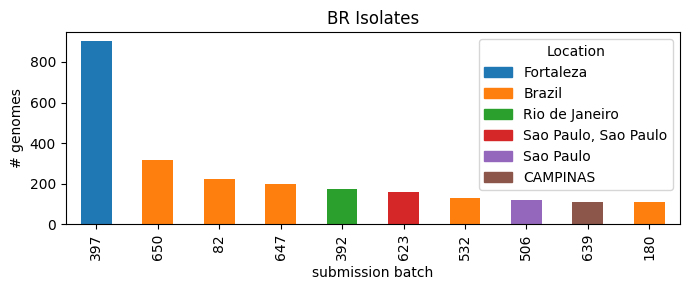

In [10]:
unique_locs = plot_data["location"].dropna().unique()
cmap = plt.get_cmap("tab10")

color_map = {
    loc: cmap(i)
    for i, loc in enumerate(unique_locs)
}

colors = plot_data["location"].map(color_map)

ax = plot_data["n"].plot(
    kind="bar",
    figsize=(7, 3),
    color=colors
)

ax.set(
    xlabel="submission batch",
    ylabel="# genomes",
    title="BR Isolates"
)

legend_handles = [
    Patch(color=color_map[loc], label=loc)
    for loc in unique_locs
]

ax.legend(handles=legend_handles, title="Location")

plt.tight_layout()
plt.show()


### PR

In [11]:
PR_batches = batches[batches['Estado'] == 'PR']

PR_batches

,n,species,location,Estado,source,years
batch,,,,,,
307,62,Escherichia coli,Londrina,PR,Urinary,2016–2019
626,53,Pseudomonas aeruginosa,Curitiba,PR,Blood,2016–2024
606,34,Staphylococcus aureus,Curitiba,PR,Blood,2017–2022
447,32,Clostridioides difficile,Curitiba,PR,Gastrointestinal,2017–2019
341,24,Escherichia coli,Maringa,PR,Gastrointestinal,2005–2019
596,8,Proteus mirabilis,"Londrina, Parana",PR,Urinary,2022–2022
612,7,Acinetobacter baumannii,Londrina,PR,Blood,2020–2023
135,6,Klebsiella pneumoniae,"Parana, Curitiba",PR,Blood,2005–2011
608,5,Klebsiella pneumoniae,Curitiba,PR,Blood,2022–2023


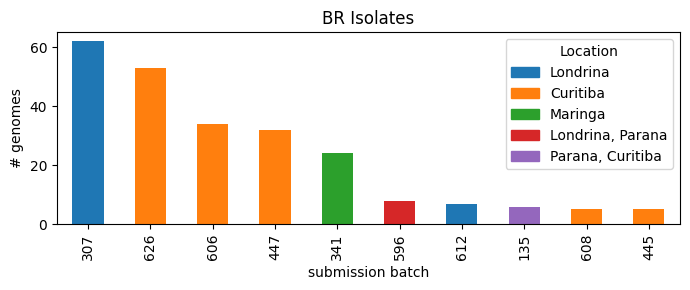

In [12]:
PR_batches_head = PR_batches.head(10).copy()

unique_locs = PR_batches_head["location"].dropna().unique()
cmap = plt.get_cmap("tab10")

color_map = {
    loc: cmap(i)
    for i, loc in enumerate(unique_locs)
}

colors = PR_batches_head["location"].map(color_map)

ax = PR_batches_head["n"].plot(
    kind="bar",
    figsize=(7, 3),
    color=colors
)

ax.set(
    xlabel="submission batch",
    ylabel="# genomes",
    title="BR Isolates"
)

legend_handles = [
    Patch(color=color_map[loc], label=loc)
    for loc in unique_locs
]

ax.legend(handles=legend_handles, title="Location")

plt.tight_layout()
plt.show()


## Genes Adquiridos

In [13]:
len(pr_finais)

297

In [14]:
len(dataset.resistome.sample_id.value_counts())

297

In [15]:
dataset.resistome.head(n=2)

,ORF_ID,Cut_Off,Pass_Bitscore,Best_Hit_Bitscore,Best_Identities,drug_class,mechanism,amr_gene_family,Predicted_Protein,CARD_Protein_Sequence,...,gene,aro_accession,model_type,gene_clean,seq_name,start,end,strand,length_nt,contig_type
0,JTUI01000001.1_17 # 22866 # 24161 # -1 # ID=1_...,Perfect,800,871.307,100.0,{peptide antibiotic},"{antibiotic efflux, antibiotic target alteration}",{pmr phosphoethanolamine transferase},MKRGLSLIPIVGGGVTLILAGVLLVYTRMLGDYGETGALYLLSMMM...,MKRGLSLIPIVGGGVTLILAGVLLVYTRMLGDYGETGALYLLSMMM...,...,cprS,ARO:3005064,protein homolog model,cprS,JTUI01000001.1,22866,24161,-1,1296,chromosome
1,JTUI01000001.1_18 # 24158 # 24829 # -1 # ID=1_...,Perfect,400,453.366,100.0,{peptide antibiotic},"{antibiotic efflux, antibiotic target alteration}",{pmr phosphoethanolamine transferase},MHIHVLVVEDNFDLAGTVIDYLEAAGVVCDHARDGQAGLNLARANR...,MHIHVLVVEDNFDLAGTVIDYLEAAGVVCDHARDGQAGLNLARANR...,...,cprR,ARO:3005063,protein homolog model,cprR,JTUI01000001.1,24158,24829,-1,672,chromosome


### Anotar

In [20]:
from src.resistome import add_mechanisms, parse_list_column

res = dataset.resistome.copy()
res = res.rename(columns={"Percentage Length of Reference Sequence": "ref_coverage"})
for col in ["drug_class", "mechanism", "amr_gene_family", "antibiotic"]:
    res[col] = parse_list_column(res[col])        # funciona tanto com string "{...}" quanto com array

# hospedeiro de cada amostra (a espécie vem dos seus metadados)
species = metadata.set_index("sample")["Species"]   # ajuste os nomes das colunas
res["host_species"] = res["sample_id"].map(species)
res["host_genus"] = res["host_species"].str.split().str[0]

res = add_mechanisms(res)


In [22]:
res.head()

,ORF_ID,Cut_Off,Pass_Bitscore,Best_Hit_Bitscore,Best_Identities,drug_class,mechanism,amr_gene_family,Predicted_Protein,CARD_Protein_Sequence,...,contig_type,host_species,host_genus,drug_category,high_confidence,bl_function,acquired_category,intrinsic,intrinsic_in,origin
0,JTUI01000001.1_17 # 22866 # 24161 # -1 # ID=1_...,Perfect,800,871.307,100.00,[peptide antibiotic],"[antibiotic efflux, antibiotic target alteration]",[pmr phosphoethanolamine transferase],MKRGLSLIPIVGGGVTLILAGVLLVYTRMLGDYGETGALYLLSMMM...,MKRGLSLIPIVGGGVTLILAGVLLVYTRMLGDYGETGALYLLSMMM...,...,chromosome,Pseudomonas aeruginosa,Pseudomonas,polymyxin/peptide,True,NaN,None,False,,core (efflux/regulator/target)
1,JTUI01000001.1_18 # 24158 # 24829 # -1 # ID=1_...,Perfect,400,453.366,100.00,[peptide antibiotic],"[antibiotic efflux, antibiotic target alteration]",[pmr phosphoethanolamine transferase],MHIHVLVVEDNFDLAGTVIDYLEAAGVVCDHARDGQAGLNLARANR...,MHIHVLVVEDNFDLAGTVIDYLEAAGVVCDHARDGQAGLNLARANR...,...,chromosome,Pseudomonas aeruginosa,Pseudomonas,polymyxin/peptide,True,NaN,None,False,,core (efflux/regulator/target)
2,JTUI01000011.1_49 # 54649 # 55857 # 1 # ID=13_...,Strict,500,750.740,99.75,[bicyclomycin-like antibiotic],[antibiotic efflux],[major facilitator superfamily (MFS) antibioti...,MPASASRIQVGSGERRLLLLLSALVAFGPLSIDMYLPSLPAIAADL...,MPASASRIQVGSGERRLLLLLSALVAFGPLSIDMYLPSLPAIAADL...,...,chromosome,Pseudomonas aeruginosa,Pseudomonas,other,True,NaN,None,False,,core (efflux/regulator/target)
3,JTUI01000011.1_66 # 72562 # 73368 # 1 # ID=13_...,Strict,500,528.094,99.25,[aminoglycoside antibiotic],[antibiotic inactivation],[APH(3')],MHDAATSMPPQAPSTWADYLAGYRWRGQGEGCSAATVHRLEAARRP...,MHDAATSMPPQAPSTWADYLAGYRWRGQGEGCSAATVHRLEAARRP...,...,chromosome,Pseudomonas aeruginosa,Pseudomonas,aminoglycoside,True,NaN,aminoglycoside: modifying enzyme,True,Pseudomonas aeruginosa,intrinsic
4,JTUI01000011.1_75 # 85724 # 86917 # -1 # ID=13...,Perfect,750,806.979,100.00,"[cephalosporin, penicillin beta-lactam, monoba...",[antibiotic inactivation],[PDC beta-lactamase],MRDTRFPCLCGIAASTLLFATTPAIAGEAPADRLKALVDAAVQPVM...,MRDTRFPCLCGIAASTLLFATTPAIAGEAPADRLKALVDAAVQPVM...,...,chromosome,Pseudomonas aeruginosa,Pseudomonas,beta-lactam,True,AmpC,beta-lactam: AmpC,True,Pseudomonas aeruginosa,intrinsic


In [59]:
set(metadata.Species.to_list())

{'Achromobacter dolens',
 'Achromobacter insuavis',
 'Achromobacter ruhlandii',
 'Achromobacter xylosoxidans',
 'Acinetobacter baumannii',
 'Acinetobacter bereziniae',
 'Acinetobacter colistiniresistens',
 'Acinetobacter courvalinii',
 'Acinetobacter nosocomialis',
 'Acinetobacter pittii',
 'Acinetobacter seifertii',
 'Actinomycetes bacterium',
 'Aeromonas australiensis',
 'Aeromonas caviae',
 'Aeromonas dhakensis',
 'Aeromonas enteropelogenes',
 'Aeromonas hydrophila',
 'Aeromonas jandaei',
 'Aeromonas veronii',
 'Aggregatibacter actinomycetemcomitans',
 'Bacillota bacterium',
 'Bacillus toyonensis',
 'Bacteroidota bacterium',
 'Bifidobacterium breve',
 'Bifidobacterium longum',
 'Bordetella pertussis',
 'Bordetella trematum',
 'Brucella oryzae',
 'Burkholderia cenocepacia',
 'Burkholderia contaminans',
 'Campylobacter coli',
 'Campylobacter jejuni',
 'Candidatus Nanogingivalaceae',
 'Candidatus Nanosynbacter',
 'Chloroflexota bacterium',
 'Citrobacter freundii',
 'Citrobacter koseri'

### Adquiridos

In [27]:
acq = res[res["high_confidence"] & (res["origin"] == "acquired")]

print(acq.shape)
acq.head()

(2302, 34)


,ORF_ID,Cut_Off,Pass_Bitscore,Best_Hit_Bitscore,Best_Identities,drug_class,mechanism,amr_gene_family,Predicted_Protein,CARD_Protein_Sequence,...,contig_type,host_species,host_genus,drug_category,high_confidence,bl_function,acquired_category,intrinsic,intrinsic_in,origin
51,JTUI01000085.1_3 # 1905 # 2648 # 1 # ID=107_3;...,Perfect,450,506.523,100.00,[aminoglycoside antibiotic],[antibiotic target alteration],[16S rRNA methyltransferase (G1405)],MSELKEKLLASKKYRDVCPDTIERIWRECSAKFKKEKDVDKAAREA...,MSELKEKLLASKKYRDVCPDTIERIWRECSAKFKKEKDVDKAAREA...,...,plasmid,Pseudomonas aeruginosa,Pseudomonas,aminoglycoside,True,NaN,aminoglycoside: 16S rRNA methyltransferase,False,,acquired
52,JTUI01000085.1_6 # 4878 # 5759 # -1 # ID=107_6...,Strict,500,542.732,100.00,[sulfonamide antibiotic],[antibiotic target replacement],[sulfonamide resistant sul],MVTVFGILNLTEDSFFDESRRLDPAGAVTAAIEMLRVGSDVVDVGP...,MVTVFGILNLTEDSFFDESRRLDPAGAVTAAIEMLRVGSDVVDVGP...,...,plasmid,Pseudomonas aeruginosa,Pseudomonas,sulfonamide,True,NaN,sulfonamide,False,,acquired
53,JTUI01000085.1_8 # 7639 # 8436 # -1 # ID=107_8...,Strict,450,523.857,98.87,[aminoglycoside antibiotic],[antibiotic inactivation],[ANT(3'')],MSEKVPAEISVQLSQALNVIGRHLESTLLAVHLYGSALDGGLKPYS...,MSEKVPAEISVQLSQALNGIGRHLESTLLAVHLYGSALDGGLKPYS...,...,plasmid,Pseudomonas aeruginosa,Pseudomonas,aminoglycoside,True,NaN,aminoglycoside: modifying enzyme,False,,acquired
54,JTUI01000085.1_9 # 8498 # 9298 # -1 # ID=107_9...,Perfect,500,544.658,100.00,"[cephalosporin, penicillin beta-lactam]",[antibiotic inactivation],"[OXA-10-like beta-lactamase, OXA beta-lactamase]",MKTFAAYVITACLSSTALASSITENTFWNKEFSAEAVNGVFVLCKS...,MKTFAAYVITACLSSTALASSITENTFWNKEFSAEAVNGVFVLCKS...,...,plasmid,Pseudomonas aeruginosa,Pseudomonas,beta-lactam,True,narrow-spectrum,beta-lactam: narrow-spectrum,False,,acquired
55,JTUI01000094.1_2 # 184 # 1014 # 1 # ID=117_2;p...,Perfect,450,567.385,100.00,[carbapenem],[antibiotic inactivation],[SPM beta-lactamase],MNSPKSRALLGFMGAFCLLLVAGAPLSAKSSDHVDLPYNLTATKID...,MNSPKSRALLGFMGAFCLLLVAGAPLSAKSSDHVDLPYNLTATKID...,...,chromosome,Pseudomonas aeruginosa,Pseudomonas,beta-lactam,True,carbapenemase (MBL),beta-lactam: carbapenemase,False,,acquired


In [35]:
acq["sample_id"].nunique()

# IDS unicas que possuem hits nesse conjunto de adquiridas

207

In [37]:
checklist = {}

checklist["PR isolates"] = len(pr_finais) # 297 ids do parana
checklist["isolates with ≥ 1 acquired gene"] = acq["sample_id"].nunique()
checklist["distinct acquired genes"] = acq["gene_clean"].nunique()
checklist["acquired occurrences on plasmid contigs"] = f"{(acq['contig_type'] == 'plasmid').mean():.0%}"

display(checklist)

{'PR isolates': 297,
 'isolates with ≥ 1 acquired gene': 207,
 'distinct acquired genes': 133,
 'acquired occurrences on plasmid contigs': '49%'}

In [40]:
per_gene = (acq.drop_duplicates(["sample_id", "gene_clean", "contig_type"]).groupby("gene_clean")
            .agg(isolates=("sample_id", "nunique"), 
                 on_plasmid=("contig_type", lambda s: (s == "plasmid").mean()),
                 category=("acquired_category", "first"), bl_function=("bl_function", "first")))


per_gene

,isolates,on_plasmid,category,bl_function
gene_clean,,,,
AAC(3)-IIc,1,1.000000,aminoglycoside: modifying enzyme,None
AAC(3)-IId,17,0.619048,aminoglycoside: modifying enzyme,None
AAC(3)-IIe,13,0.538462,aminoglycoside: modifying enzyme,None
AAC(3)-IVa,1,0.500000,aminoglycoside: modifying enzyme,None
AAC(3)-VIa,4,0.333333,aminoglycoside: modifying enzyme,None
...,...,...,...,...
tet(B),27,0.656250,tetracycline,None
tet(C),3,1.000000,tetracycline,None
tet(D),2,0.000000,tetracycline,None


In [44]:
checklist["acquired genes seen on a plasmid contig at least once"] = f"{(per_gene['on_plasmid'] > 0).sum()} of {len(per_gene)}"

checklist

{'PR isolates': 297,
 'isolates with ≥ 1 acquired gene': 207,
 'distinct acquired genes': 133,
 'acquired occurrences on plasmid contigs': '49%',
 'acquired genes seen on a plasmid contig at least once': '100 of 133'}

In [45]:
per_cat = (acq.assign(p=acq["contig_type"] == "plasmid").groupby("acquired_category")
           .agg(occurrences=("p", "size"), 
                on_plasmid=("p", "mean")).sort_values("occurrences", ascending=False))

per_cat

,occurrences,on_plasmid
acquired_category,,
aminoglycoside: modifying enzyme,647,0.500773
sulfonamide,256,0.503906
MLS,244,0.622951
beta-lactam: narrow-spectrum,205,0.580488
tetracycline,200,0.530000
trimethoprim,148,0.378378
antiseptic: qacE/qacEdelta1 (class 1 integron),138,0.405797
beta-lactam: ESBL,137,0.204380
phenicol,93,0.548387


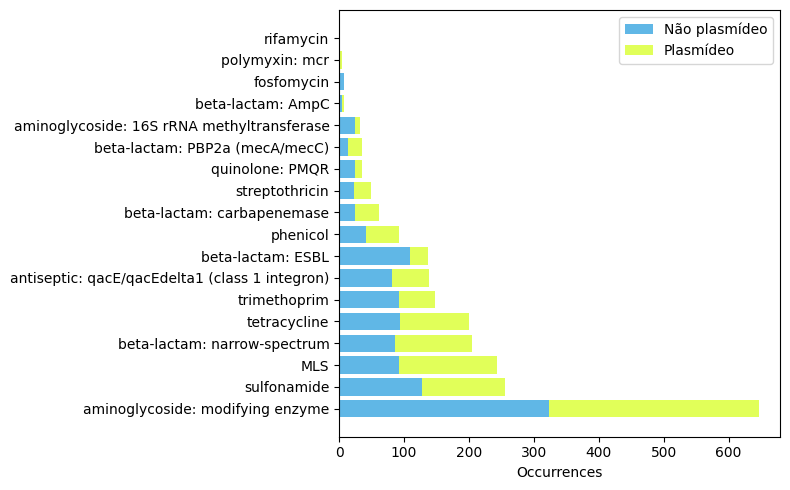

In [151]:
total = per_cat['occurrences']
plasmid = total * per_cat['on_plasmid']
non_plasmid = total - plasmid

fig, ax = plt.subplots(figsize=(8, 5))

ax.barh(
    per_cat.index,
    non_plasmid,
    color='#60b7e6',
    label='Não plasmídeo'
)

ax.barh(
    per_cat.index,
    plasmid,
    left=non_plasmid,
    color="#e1ff59",
    label='Plasmídeo'
)

ax.set_xlabel('Occurrences')
ax.legend()

plt.tight_layout()
plt.show()


In [156]:
per_cat_beta = per_cat[per_cat.index.str.contains('beta')]

per_cat_beta

,occurrences,on_plasmid
acquired_category,,
beta-lactam: narrow-spectrum,205,0.580488
beta-lactam: ESBL,137,0.204380
beta-lactam: carbapenemase,61,0.606557
beta-lactam: PBP2a (mecA/mecC),35,0.628571
beta-lactam: AmpC,8,0.500000


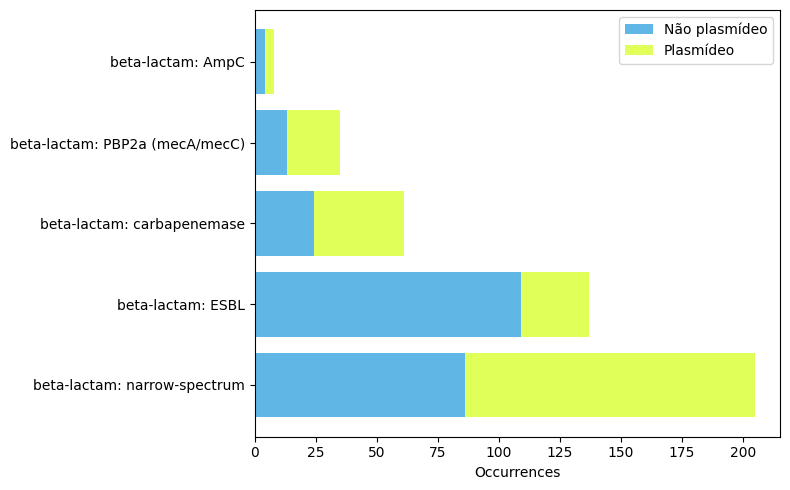

In [158]:
total = per_cat_beta['occurrences']
plasmid = total * per_cat_beta['on_plasmid']
non_plasmid = total - plasmid

fig, ax = plt.subplots(figsize=(8, 5))

ax.barh(
    per_cat_beta.index,
    non_plasmid,
    color='#60b7e6',
    label='Não plasmídeo'
)

ax.barh(
    per_cat_beta.index,
    plasmid,
    left=non_plasmid,
    color='#e1ff59',
    label='Plasmídeo'
)

ax.set_xlabel('Occurrences')
ax.legend()

plt.tight_layout()
plt.show()


Genes com:
- mais de 5 isolados
- em plasmideos

In [160]:
mais_comuns = per_gene[(per_gene["isolates"] >= 5) & (per_gene["on_plasmid"] >= 0.7)].sort_values("on_plasmid", ascending=False).round(2)

mais_comuns

,isolates,on_plasmid,category,bl_function
gene_clean,,,,
armA,5,1.00,aminoglycoside: 16S rRNA methyltransferase,None
PC1,30,1.00,beta-lactam: narrow-spectrum,narrow-spectrum
aadA7,24,1.00,aminoglycoside: modifying enzyme,None
Mrx,35,0.97,MLS,None
OXA-10-like,25,0.96,beta-lactam: narrow-spectrum,narrow-spectrum
KPC-2,15,0.94,beta-lactam: carbapenemase,carbapenemase (serine)
floR,12,0.92,phenicol,None
cmx,26,0.88,phenicol,None
msrE,8,0.88,MLS,None


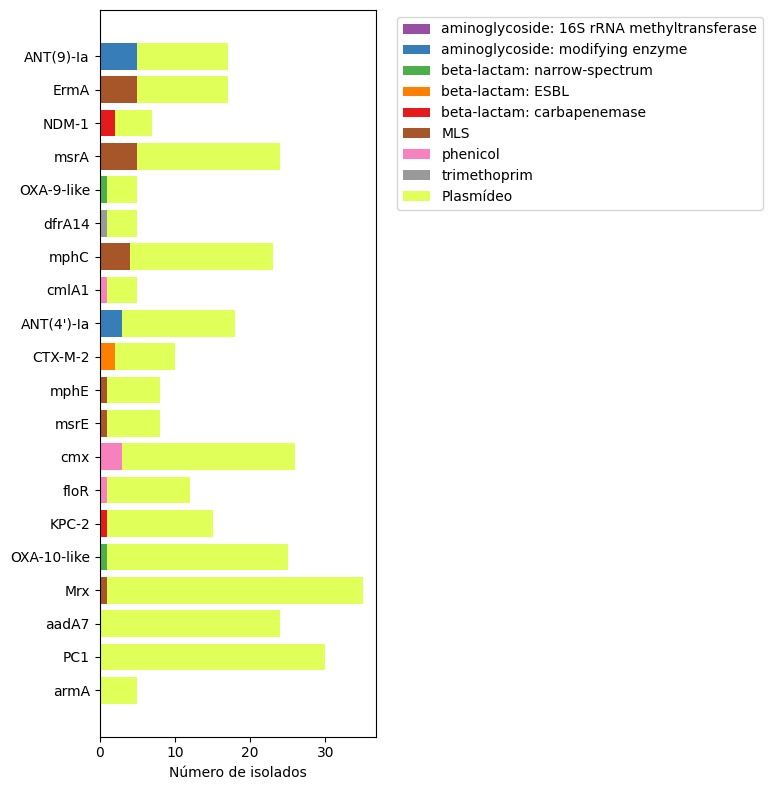

In [166]:
category_colors = {
    'aminoglycoside: 16S rRNA methyltransferase': '#984ea3',
    'aminoglycoside: modifying enzyme': '#377eb8',
    'beta-lactam: narrow-spectrum': '#4daf4a',
    'beta-lactam: ESBL': '#ff7f00',
    'beta-lactam: carbapenemase': '#e41a1c',
    'MLS': '#a65628',
    'phenicol': '#f781bf',
    'trimethoprim': '#999999',
}

plasmid_n = (
    mais_comuns['isolates'] * mais_comuns['on_plasmid']
).round().astype(int)

chromosome_n = mais_comuns['isolates'] - plasmid_n

colors = mais_comuns['category'].map(category_colors)

fig, ax = plt.subplots(figsize=(8, 8))

# Cromossômico
ax.barh(
    mais_comuns.index,
    chromosome_n,
    color=colors,
    label='Cromossômico'
)

# Plasmidial
ax.barh(
    mais_comuns.index,
    plasmid_n,
    left=chromosome_n,
    color='#e1ff59',
    label='Plasmídeo'
)

ax.set_xlabel('Número de isolados')

from matplotlib.patches import Patch

legend_categories = [
    Patch(facecolor=color, label=category)
    for category, color in category_colors.items()
]

legend_main = [
    Patch(facecolor='#e1ff59', label='Plasmídeo')
]

ax.legend(
    handles=legend_categories + legend_main,
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)


plt.tight_layout()
plt.show()

In [49]:
TARGET_RX = r"^(?:KPC|NDM|VIM|IMP|SPM|GES)-|^OXA-(?:23|24|40|48|58)(?:-like)?$|^CTX-M-|^arm|^rmt|^MCR-"
targets = per_gene[per_gene.index.str.contains(TARGET_RX)].sort_values("isolates", ascending=False).round(2)
for g in ["KPC-2", "NDM-1", "armA", "CTX-M-2", "CTX-M-15"]:
    if g in per_gene.index:
        checklist[f"{g} on plasmid contigs"] = f"{per_gene.loc[g, 'on_plasmid']:.0%} (n={per_gene.loc[g, 'isolates']})"
mcr = per_gene[per_gene.index.str.startswith("MCR-")]
checklist["mcr on plasmid contigs"] = f"{mcr['on_plasmid'].mean():.0%} (n={mcr['isolates'].sum()})"
targets

,isolates,on_plasmid,category,bl_function
gene_clean,,,,
CTX-M-15,27,0.14,beta-lactam: ESBL,ESBL
rmtD,24,0.04,aminoglycoside: 16S rRNA methyltransferase,None
SPM-1,21,0.57,beta-lactam: carbapenemase,carbapenemase (MBL)
KPC-2,15,0.94,beta-lactam: carbapenemase,carbapenemase (serine)
CTX-M-8,11,0.08,beta-lactam: ESBL,ESBL
CTX-M-14,10,0.18,beta-lactam: ESBL,ESBL
CTX-M-2,10,0.83,beta-lactam: ESBL,ESBL
OXA-23-like,7,0.00,beta-lactam: carbapenemase,carbapenemase (serine)
NDM-1,7,0.71,beta-lactam: carbapenemase,carbapenemase (MBL)


In [169]:
targets.sort_values('on_plasmid', ascending=False).head(n=10)

,isolates,on_plasmid,category,bl_function
gene_clean,,,,
MCR-1.5,1,1.00,polymyxin: mcr,None
MCR-1.1,3,1.00,polymyxin: mcr,None
MCR-1.34,1,1.00,polymyxin: mcr,None
GES-5,1,1.00,beta-lactam: carbapenemase,carbapenemase (serine)
armA,5,1.00,aminoglycoside: 16S rRNA methyltransferase,None
KPC-2,15,0.94,beta-lactam: carbapenemase,carbapenemase (serine)
CTX-M-2,10,0.83,beta-lactam: ESBL,ESBL
NDM-1,7,0.71,beta-lactam: carbapenemase,carbapenemase (MBL)
rmtB,2,0.67,aminoglycoside: 16S rRNA methyltransferase,None


In [172]:
targets_lista = targets.index.to_list()
targets_lista

['CTX-M-15',
 'rmtD',
 'SPM-1',
 'KPC-2',
 'CTX-M-8',
 'CTX-M-14',
 'CTX-M-2',
 'OXA-23-like',
 'NDM-1',
 'CTX-M-55',
 'armA',
 'MCR-1.1',
 'CTX-M-27',
 'CTX-M-24',
 'CTX-M-157',
 'rmtB',
 'OXA-58-like',
 'CTX-M-3',
 'IMP-74',
 'MCR-1.34',
 'KPC-3',
 'GES-5',
 'MCR-1.5']

In [176]:
acq_targets = acq[
    acq['gene_clean'].isin(targets_lista)
]

acq_targets.head()

,ORF_ID,Cut_Off,Pass_Bitscore,Best_Hit_Bitscore,Best_Identities,drug_class,mechanism,amr_gene_family,Predicted_Protein,CARD_Protein_Sequence,...,contig_type,host_species,host_genus,drug_category,high_confidence,bl_function,acquired_category,intrinsic,intrinsic_in,origin
51,JTUI01000085.1_3 # 1905 # 2648 # 1 # ID=107_3;...,Perfect,450,506.523,100.0,[aminoglycoside antibiotic],[antibiotic target alteration],[16S rRNA methyltransferase (G1405)],MSELKEKLLASKKYRDVCPDTIERIWRECSAKFKKEKDVDKAAREA...,MSELKEKLLASKKYRDVCPDTIERIWRECSAKFKKEKDVDKAAREA...,...,plasmid,Pseudomonas aeruginosa,Pseudomonas,aminoglycoside,True,NaN,aminoglycoside: 16S rRNA methyltransferase,False,,acquired
55,JTUI01000094.1_2 # 184 # 1014 # 1 # ID=117_2;p...,Perfect,450,567.385,100.0,[carbapenem],[antibiotic inactivation],[SPM beta-lactamase],MNSPKSRALLGFMGAFCLLLVAGAPLSAKSSDHVDLPYNLTATKID...,MNSPKSRALLGFMGAFCLLLVAGAPLSAKSSDHVDLPYNLTATKID...,...,chromosome,Pseudomonas aeruginosa,Pseudomonas,beta-lactam,True,carbapenemase (MBL),beta-lactam: carbapenemase,False,,acquired
176,JTMJ01000087.1_2 # 1066 # 1941 # -1 # ID=100_2...,Perfect,500,599.356,100.0,[cephalosporin],[antibiotic inactivation],[CTX-M beta-lactamase],MMTQSIRRSMLTVMATLPLLFSSATLHAQANSVQQQLEALEKSSGG...,MMTQSIRRSMLTVMATLPLLFSSATLHAQANSVQQQLEALEKSSGG...,...,plasmid,Pseudomonas aeruginosa,Pseudomonas,beta-lactam,True,ESBL,beta-lactam: ESBL,False,,acquired
401,QGGA01000087.1_1 # 2 # 877 # -1 # ID=7_1;parti...,Perfect,500,592.423,100.0,[cephalosporin],[antibiotic inactivation],[CTX-M beta-lactamase],MVTKRVQRMMFAAAACIPLLLGSAPLYAQTSAVQQKLAALEKSSGG...,MVTKRVQRMMFAAAACIPLLLGSAPLYAQTSAVQQKLAALEKSSGG...,...,chromosome,Proteus mirabilis,Proteus,beta-lactam,True,ESBL,beta-lactam: ESBL,False,,acquired
420,QWFV01000187.1_1 # 232 # 1005 # 1 # ID=98_1;pa...,Strict,500,534.643,100.0,"[penicillin beta-lactam, carbapenem]",[antibiotic inactivation],"[OXA-58-like beta-lactamase, OXA beta-lactamase]",MSRAKTSTIPQVNNSIIDQNVQALFNEISADAVFVTYDGQNIKKYG...,MKLLKILSLVCLSISIGACAEHSMSRAKTSTIPQVNNSIIDQNVQA...,...,plasmid,Acinetobacter bereziniae,Acinetobacter,beta-lactam,True,carbapenemase (serine),beta-lactam: carbapenemase,False,,acquired


In [180]:
crosstab_target_species = pd.crosstab(acq_targets['gene_clean'], acq_targets['host_species'])

crosstab_target_species.head()

host_species,Acinetobacter baumannii,Acinetobacter bereziniae,Acinetobacter colistiniresistens,Escherichia coli,Klebsiella aerogenes,Klebsiella pneumoniae,Klebsiella variicola,Proteus mirabilis,Pseudomonas aeruginosa,Raoultella planticola
gene_clean,,,,,,,,,,
CTX-M-14,0,0,0,14,0,2,0,2,0,0
CTX-M-15,1,0,0,34,0,11,0,0,0,1
CTX-M-157,0,0,0,2,0,0,0,0,0,0
CTX-M-2,0,0,0,14,2,2,0,1,1,0
CTX-M-24,0,0,0,6,0,0,0,0,0,0


In [189]:
from matplotlib.colors import LogNorm

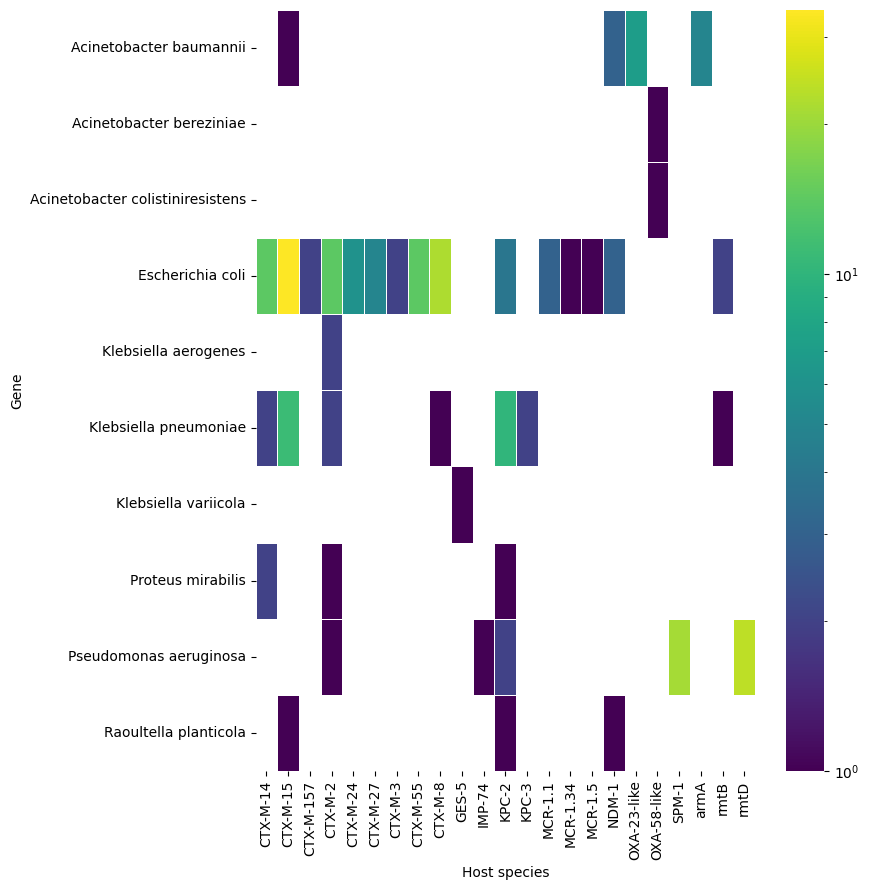

In [191]:
plt.figure(figsize=(9, 9))

sns.heatmap(
    crosstab_target_species.T,
    annot=False,
    fmt='g',
    cmap='viridis',
    linewidths=0.5,
    linecolor='white',
    norm=LogNorm(
        vmin=1,
        vmax=crosstab_target_species.to_numpy().max()
    )
)

plt.xlabel('Host species')
plt.ylabel('Gene')
plt.tight_layout()
plt.show()

PC1: 25.2%
PC2: 19.2%


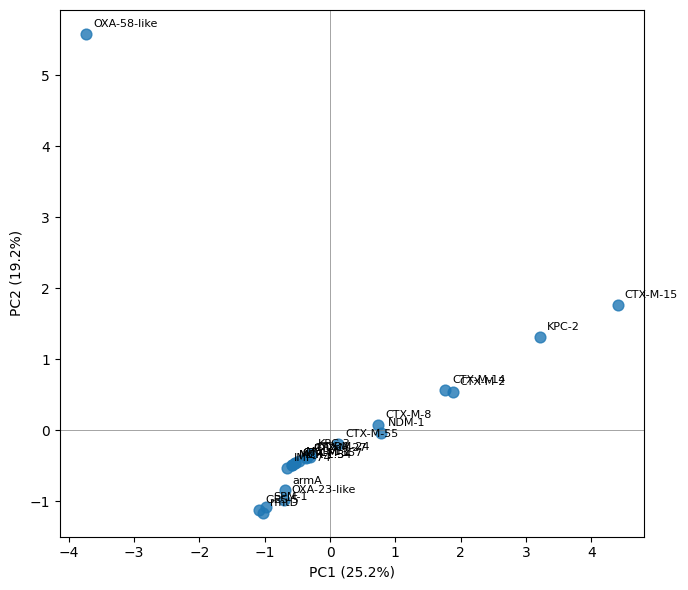

In [192]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd
import matplotlib.pyplot as plt

# dados: genes × espécies
X = crosstab_target_species.copy()

# padronizar cada espécie
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    index=X.index,
    columns=['PC1', 'PC2']
)

print(
    f"PC1: {pca.explained_variance_ratio_[0]*100:.1f}%"
)
print(
    f"PC2: {pca.explained_variance_ratio_[1]*100:.1f}%"
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    s=60,
    alpha=0.8
)

for gene, row in pca_df.iterrows():
    ax.annotate(
        gene,
        (row['PC1'], row['PC2']),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=8
    )

ax.axhline(0, color='gray', lw=0.5)
ax.axvline(0, color='gray', lw=0.5)

ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)
ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.tight_layout()
plt.show()


PC1: 29.9%
PC2: 17.6%


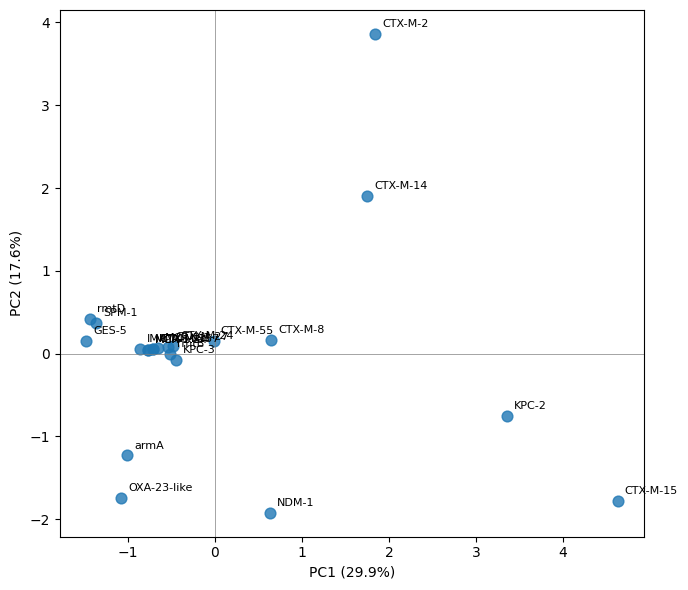

In [199]:
X = X.drop('OXA-58-like')

# padronizar cada espécie
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    index=X.index,
    columns=['PC1', 'PC2']
)

print(
    f"PC1: {pca.explained_variance_ratio_[0]*100:.1f}%"
)
print(
    f"PC2: {pca.explained_variance_ratio_[1]*100:.1f}%"
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    s=60,
    alpha=0.8
)

for gene, row in pca_df.iterrows():
    ax.annotate(
        gene,
        (row['PC1'], row['PC2']),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=8
    )

ax.axhline(0, color='gray', lw=0.5)
ax.axvline(0, color='gray', lw=0.5)

ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)
ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.tight_layout()
plt.show()


In [208]:
plas.head(n=1)

,ORF_ID,Cut_Off,Pass_Bitscore,Best_Hit_Bitscore,Best_Identities,drug_class,mechanism,amr_gene_family,Predicted_Protein,CARD_Protein_Sequence,...,contig_type,host_species,host_genus,drug_category,high_confidence,bl_function,acquired_category,intrinsic,intrinsic_in,origin
51,JTUI01000085.1_3 # 1905 # 2648 # 1 # ID=107_3;...,Perfect,450,506.523,100.0,[aminoglycoside antibiotic],[antibiotic target alteration],[16S rRNA methyltransferase (G1405)],MSELKEKLLASKKYRDVCPDTIERIWRECSAKFKKEKDVDKAAREA...,MSELKEKLLASKKYRDVCPDTIERIWRECSAKFKKEKDVDKAAREA...,...,plasmid,Pseudomonas aeruginosa,Pseudomonas,aminoglycoside,True,NaN,aminoglycoside: 16S rRNA methyltransferase,False,,acquired


In [212]:
plas = acq[acq["contig_type"] == "plasmid"]


# 1) tabela longa: quantos isolados de cada espécie têm cada gene/mecanismo em plasmídeo
tabela = (plas.groupby(["host_species", "origin", "acquired_category", "gene_clean"])
              .agg(n_isolados=("sample_id", "nunique"))
              .reset_index()
              .sort_values("n_isolados", ascending=False))

# prevalência dentro da espécie (denominador = isolados da espécie no dataset todo)
n_sp = res.groupby("host_species")["sample_id"].nunique()
tabela["prev_sp"] = tabela["n_isolados"] / tabela["host_species"].map(n_sp)

print(tabela.head(30))

               host_species    origin  \
55         Escherichia coli  acquired   
81         Escherichia coli  acquired   
80         Escherichia coli  acquired   
83         Escherichia coli  acquired   
51         Escherichia coli  acquired   
47         Escherichia coli  acquired   
198   Staphylococcus aureus  acquired   
37         Escherichia coli  acquired   
39         Escherichia coli  acquired   
165  Pseudomonas aeruginosa  acquired   
169  Pseudomonas aeruginosa  acquired   
54         Escherichia coli  acquired   
90         Escherichia coli  acquired   
171  Pseudomonas aeruginosa  acquired   
197   Staphylococcus aureus  acquired   
84         Escherichia coli  acquired   
64         Escherichia coli  acquired   
192   Staphylococcus aureus  acquired   
193   Staphylococcus aureus  acquired   
196   Staphylococcus aureus  acquired   
199   Staphylococcus aureus  acquired   
194   Staphylococcus aureus  acquired   
191   Staphylococcus aureus  acquired   
52         Esche

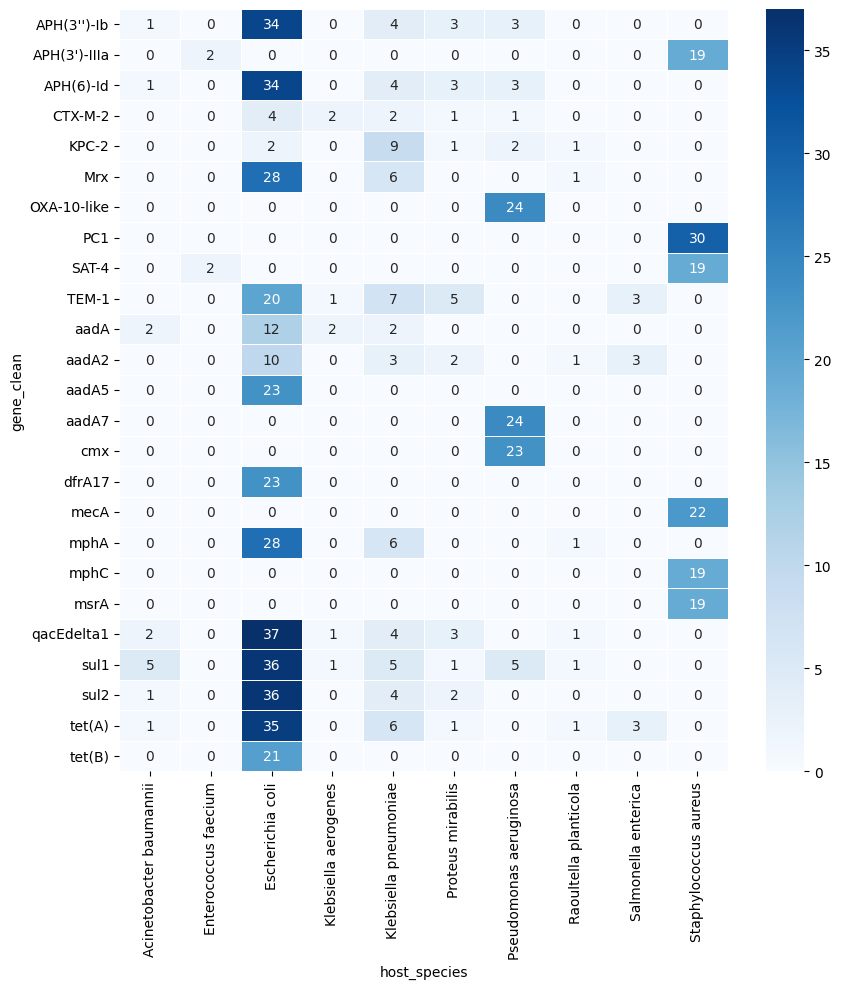

In [213]:
top_sp   = plas["host_species"].value_counts().head(10).index
top_gene = plas["gene_clean"].value_counts().head(25).index

m = (plas[plas["host_species"].isin(top_sp) & plas["gene_clean"].isin(top_gene)]
        .groupby(["gene_clean", "host_species"])["sample_id"].nunique()
        .unstack(fill_value=0))

plt.figure(figsize=(9, 10))
sns.heatmap(m, annot=True, fmt="d", cmap="Blues", linewidths=.5)
plt.tight_layout(); plt.show()

In [224]:
ids = set(res["sample_id"].unique())
print("exemplos res:", list(ids)[:3])
print("exemplos metadata:", metadata["sample"].head(3).tolist())
for c in ["sample", "BioSample"]:
    print(c, "->", metadata[c].isin(ids).sum(), "casam de", metadata[c].nunique())

exemplos res: ['GCA_042875775.1', 'GCA_049377585.1', 'GCA_042875835.1']
exemplos metadata: ['GCA_000268125.1', 'GCA_016074895.1', 'GCA_000249675.2']
sample -> 297 casam de 7038
BioSample -> 0 casam de 7038


In [ ]:
# limpa o que sobrou dos merges anteriores
res = res.drop(columns=["BioSample", "batch", "lote", "BioSample_x", "BioSample_y",
                        "lote_x", "lote_y", "batch_x", "batch_y"], errors="ignore")

res = res.merge(metadata[["sample", "batch"]].drop_duplicates("sample"),
                left_on="sample_id", right_on="sample", how="left").drop(columns="sample")
res = res.merge(b[["lote"]], left_on="batch", right_index=True, how="left")

print("sem batch:", res["batch"].isna().sum(), "de", len(res))   # deve ser ~0

sem batch: 0 de 12531


In [231]:
PR_batches = PR_batches.reset_index()

In [237]:
PR_batches = PR_batches.reset_index()
PR_batches['lote'] = PR_batches['batch']
PR_batches.head()

,index,batch,n,species,location,Estado,source,years,lote
0,0,307,62,Escherichia coli,Londrina,PR,Urinary,2016–2019,307
1,1,626,53,Pseudomonas aeruginosa,Curitiba,PR,Blood,2016–2024,626
2,2,606,34,Staphylococcus aureus,Curitiba,PR,Blood,2017–2022,606
3,3,447,32,Clostridioides difficile,Curitiba,PR,Gastrointestinal,2017–2019,447
4,4,341,24,Escherichia coli,Maringa,PR,Gastrointestinal,2005–2019,341


res com lote (PR): 11613 de 12531
hits plasmidiais no PR: 1086 | isolados: 163
                                      lote             host_species  \
52         307 | E. coli | Londrina (n=62)         Escherichia coli   
71         307 | E. coli | Londrina (n=62)         Escherichia coli   
72         307 | E. coli | Londrina (n=62)         Escherichia coli   
74         307 | E. coli | Londrina (n=62)         Escherichia coli   
48         307 | E. coli | Londrina (n=62)         Escherichia coli   
45         307 | E. coli | Londrina (n=62)         Escherichia coli   
36         307 | E. coli | Londrina (n=62)         Escherichia coli   
35         307 | E. coli | Londrina (n=62)         Escherichia coli   
246  626 | P. aeruginosa | Curitiba (n=53)   Pseudomonas aeruginosa   
201      606 | S. aureus | Curitiba (n=34)    Staphylococcus aureus   
248  626 | P. aeruginosa | Curitiba (n=53)   Pseudomonas aeruginosa   
243  626 | P. aeruginosa | Curitiba (n=53)   Pseudomonas aeruginosa  

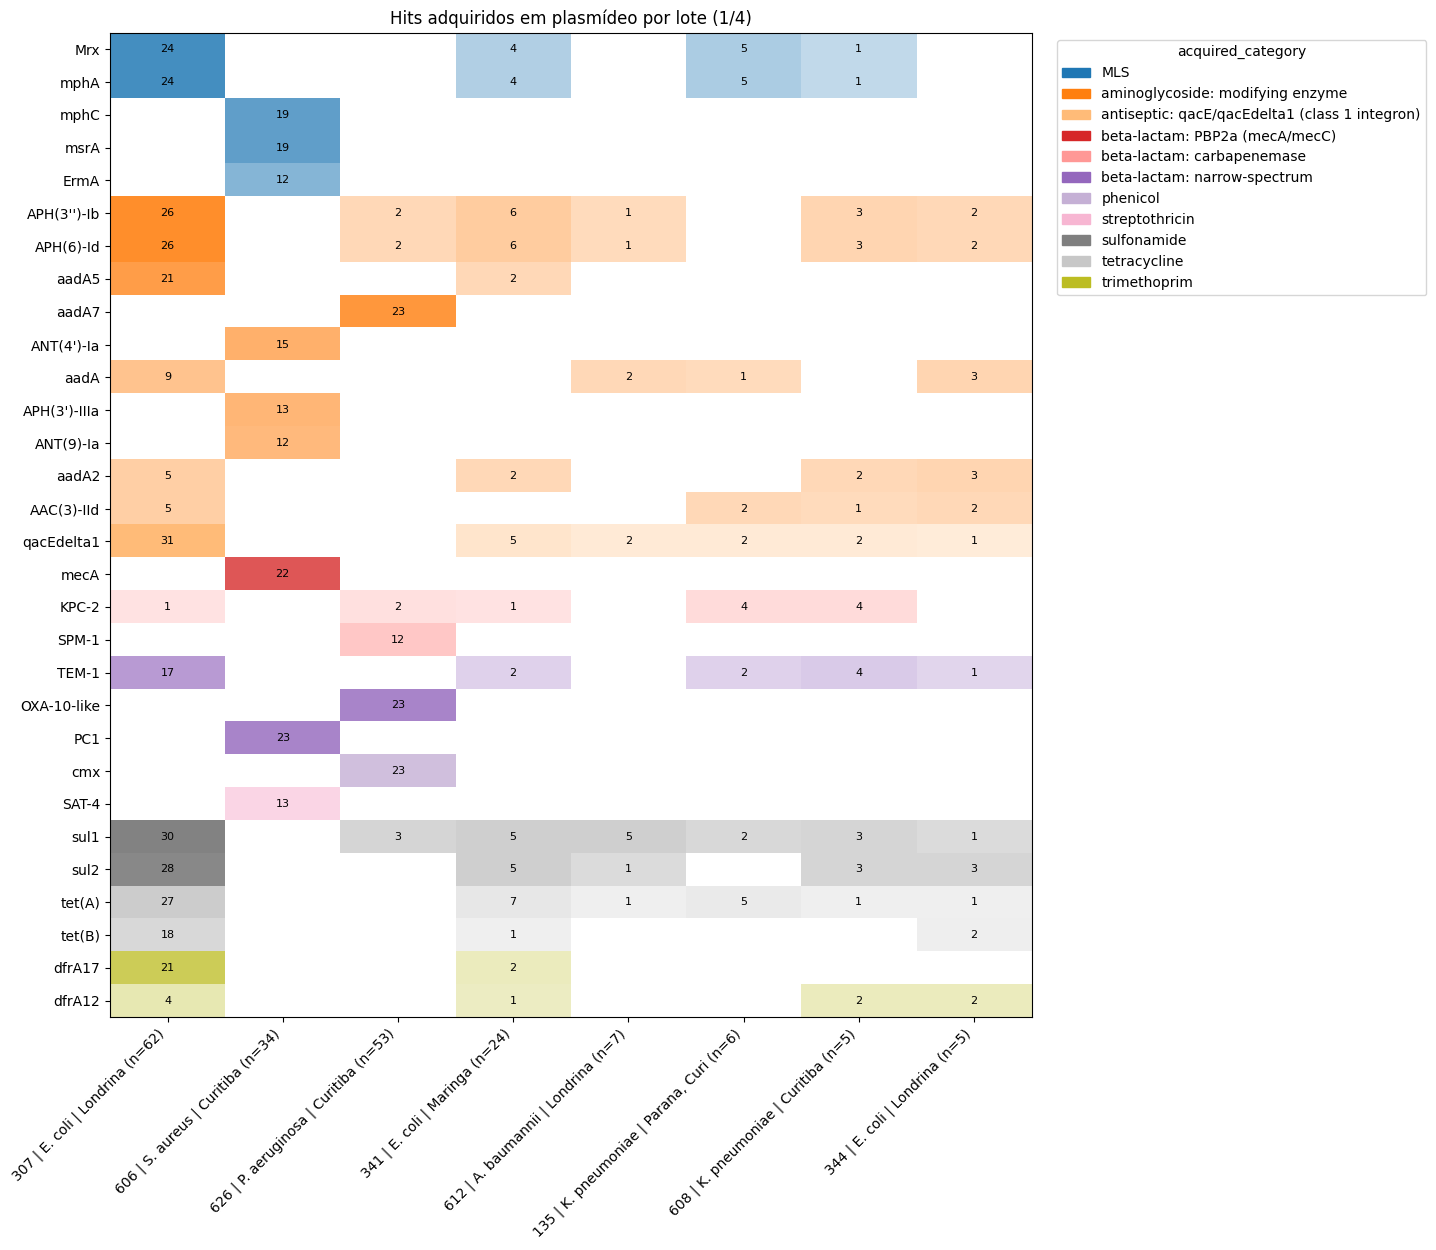

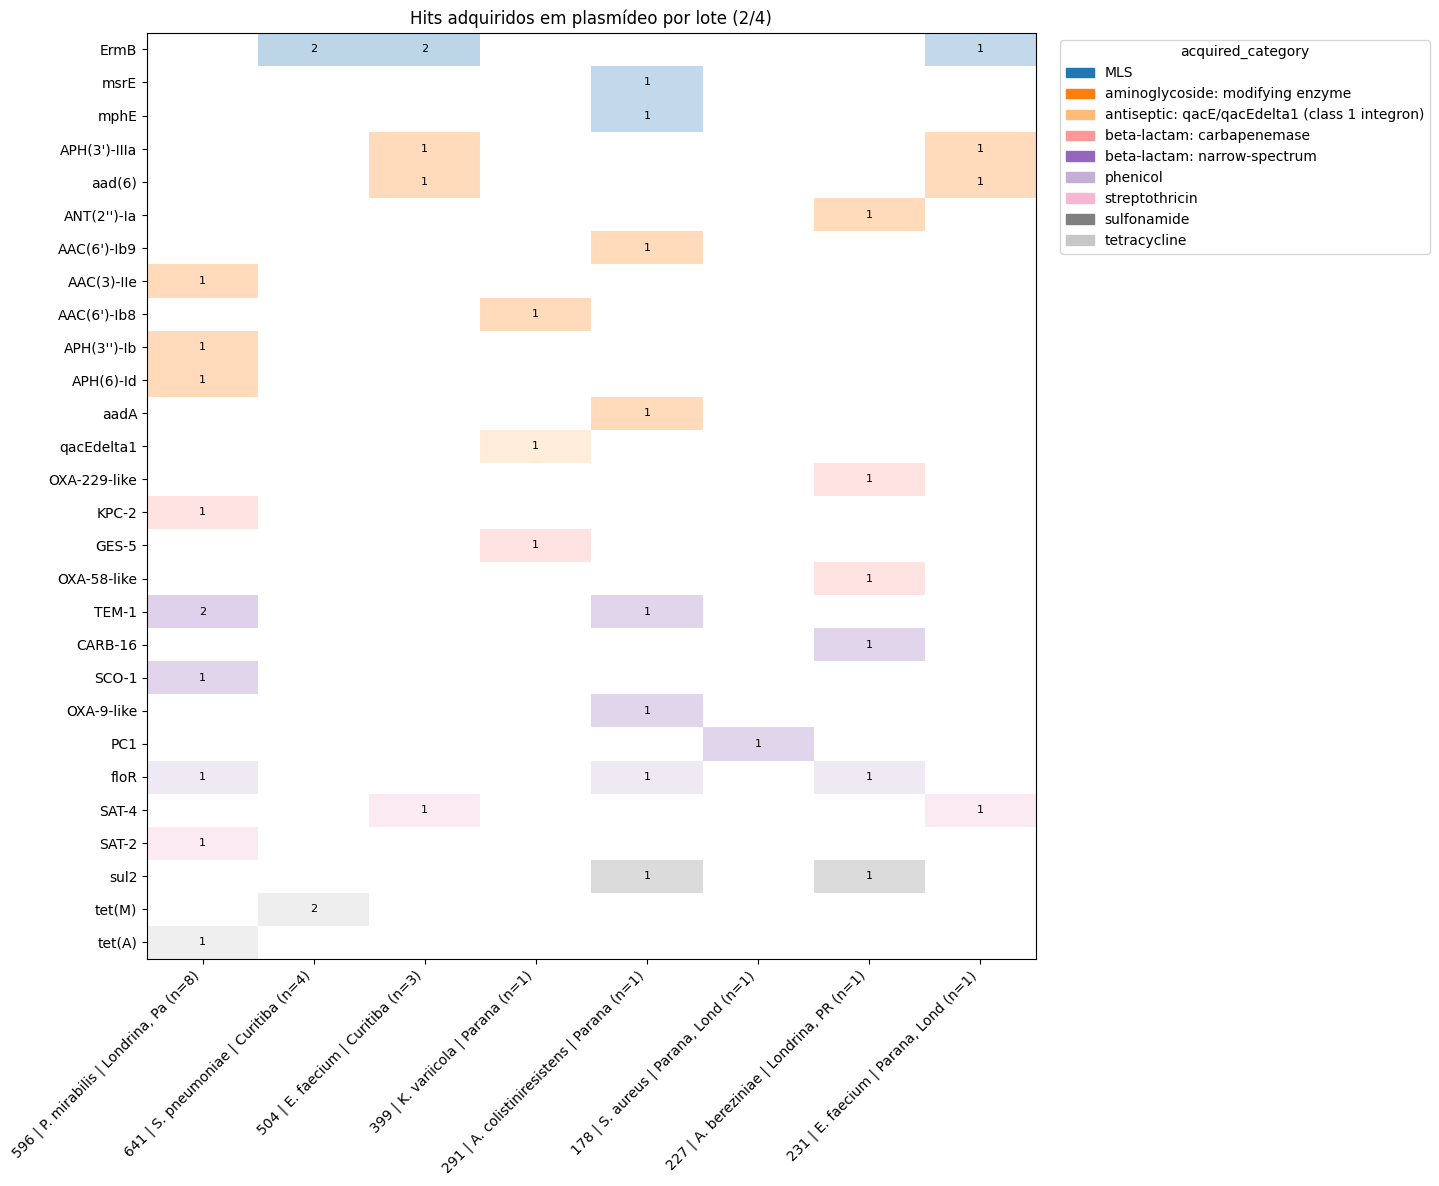

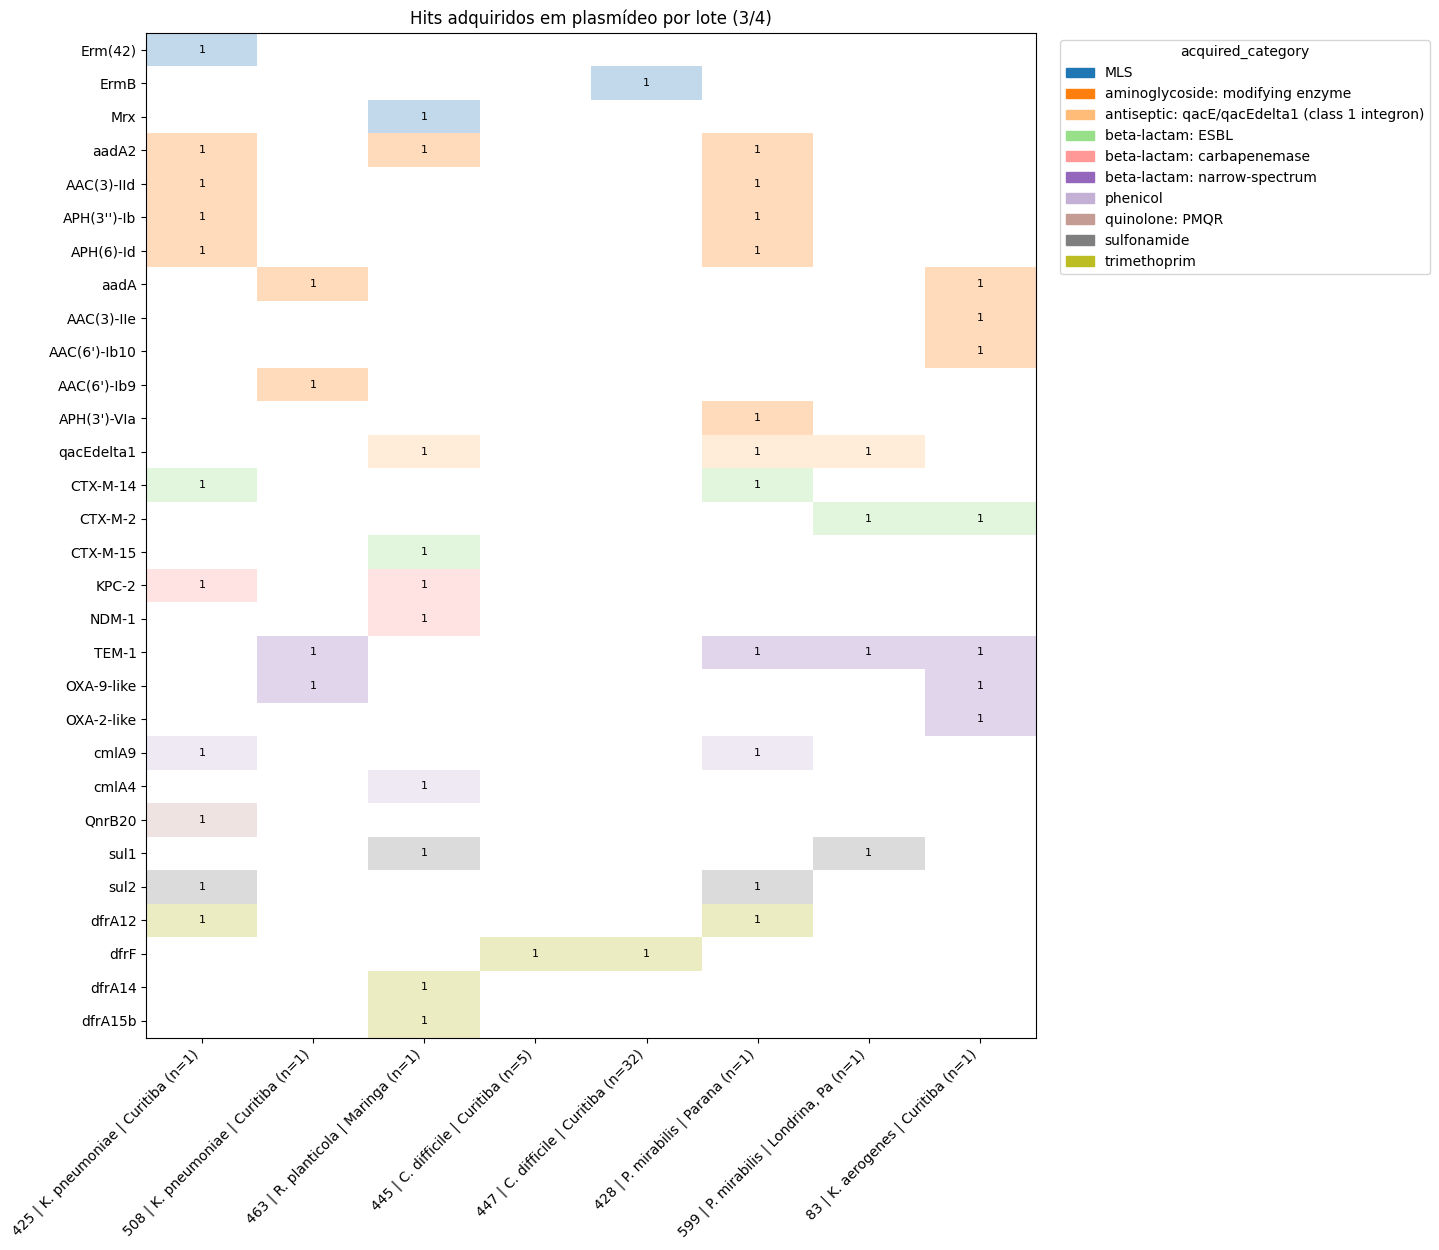

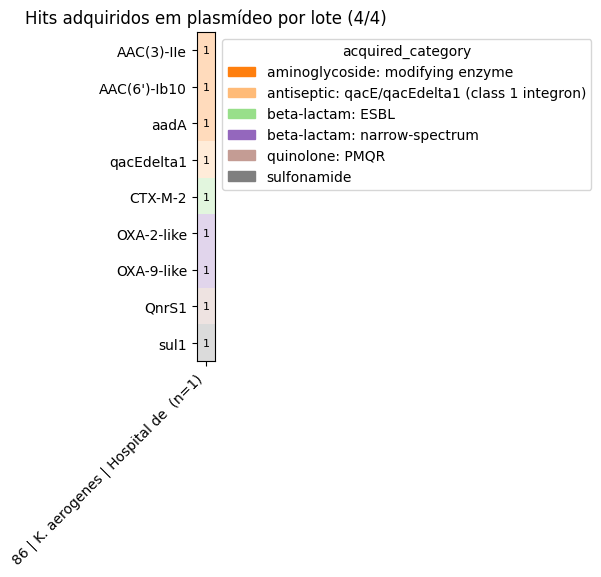

In [238]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch

# ---- 1) rótulo do lote (a partir do PR_batches atual) ----
b = PR_batches.drop_duplicates("batch").set_index("batch").copy()
b["lote"] = (b.index.astype(str) + " | "
             + b["species"].str.replace(r"^(\w)\w+ ", r"\1. ", regex=True) + " | "
             + b["location"].str.slice(0, 12) + " (n=" + b["n"].astype(str) + ")")

res = res.drop(columns="lote", errors="ignore").merge(b[["lote"]], left_on="batch", right_index=True, how="left")
print("res com lote (PR):", res["lote"].notna().sum(), "de", len(res))

# ---- 2) subconjuntos ----
acq  = res[res["high_confidence"] & (res["origin"] == "acquired")]
plas = acq[(acq["contig_type"] == "plasmid") & acq["lote"].notna()].explode("mechanism")   # mechanism é lista
print("hits plasmidiais no PR:", len(plas), "| isolados:", plas["sample_id"].nunique())

# ---- 3) tabela gene / mecanismo / espécie / lote ----
tabela = (plas.groupby(["lote", "host_species", "acquired_category", "mechanism", "gene_clean"])
              .agg(n_isolados=("sample_id", "nunique")).reset_index()
              .sort_values("n_isolados", ascending=False))
tabela["prev_lote"] = tabela["n_isolados"] / tabela["lote"].str.extract(r"n=(\d+)")[0].astype(int)
print(tabela.head(30))

# ---- 4) heatmap por lote, colorido por categoria ----
N_LOTE, TOP_GENES = 8, 30
gene_cat = plas.groupby("gene_clean")["acquired_category"].agg(lambda s: s.mode().iat[0])
cor = {c: plt.cm.tab20.colors[i % 20] for i, c in enumerate(sorted(gene_cat.unique()))}

col_ord = plas.groupby("lote")["sample_id"].nunique().sort_values(ascending=False)
grupos  = [list(col_ord.index[i:i + N_LOTE]) for i in range(0, len(col_ord), N_LOTE)]
vmax = plas.groupby(["gene_clean", "lote"])["sample_id"].nunique().max()

for k, cols in enumerate(grupos, 1):
    m = (plas[plas["lote"].isin(cols)].groupby(["gene_clean", "lote"])["sample_id"].nunique()
           .unstack(fill_value=0).reindex(columns=cols, fill_value=0))
    m = m.loc[m.sum(axis=1).nlargest(TOP_GENES).index]
    m = (m.assign(_cat=gene_cat.reindex(m.index), _tot=m.sum(axis=1))
           .sort_values(["_cat", "_tot"], ascending=[True, False]))
    cat_g = m.pop("_cat"); m = m.drop(columns="_tot")

    img = np.ones((*m.shape, 3))
    for i, g in enumerate(m.index):
        base = np.array(to_rgb(cor[cat_g[g]]))
        for j in range(m.shape[1]):
            if m.iat[i, j] > 0:
                img[i, j] = 1 - (0.25 + 0.75 * m.iat[i, j] / vmax) * (1 - base)

    fig, ax = plt.subplots(figsize=(1.3 * len(cols) + 4, 0.32 * len(m) + 3))
    ax.imshow(img, aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            if m.iat[i, j] > 0:
                ax.text(j, i, int(m.iat[i, j]), ha="center", va="center", fontsize=8)
    ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
    ax.set_yticks(range(len(m)), m.index)
    ax.set_title(f"Hits adquiridos em plasmídeo por lote ({k}/{len(grupos)})")
    ax.legend(handles=[Patch(color=cor[c], label=c) for c in cat_g.unique()],
              title="acquired_category", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout(); plt.show()